# 2. Regression Analysis:
A. Predict the price of the Uber ride from a given pickup point to the agreed drop-off
location. Perform following tasks:<br>
1. Pre-process the dataset.<br>
2. Identify outliers.<br>
3. Check the correlation.<br>
4. Implement linear regression and ridge, Lasso regression models.<br>
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.<br>
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
# 1. LOAD DATASET
df = pd.read_csv("uber.csv")
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [8]:
df = df.drop(columns=["key", "pickup_datetime", "Unnamed: 0"],
             errors="ignore").dropna()

In [9]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5


In [10]:
# 2. REMOVE OUTLIERS
q1 = df["fare_amount"].quantile(0.25)
q3 = df["fare_amount"].quantile(0.75)
iqr = q3 - q1

df = df[(df["fare_amount"] > 0) & (df["fare_amount"].between(q1 - 1.5*iqr, q3 + 1.5*iqr))]


Correlation with Fare:
fare_amount          1.000000
pickup_longitude     0.000425
pickup_latitude      0.002573
dropoff_longitude   -0.002299
dropoff_latitude     0.000466
passenger_count      0.012618
Name: fare_amount, dtype: float64


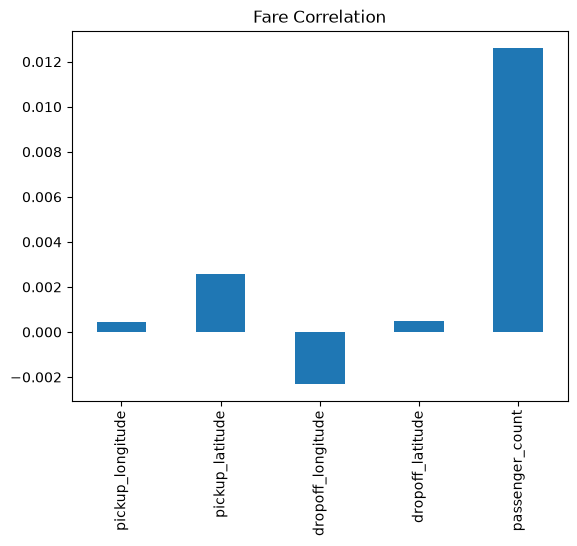

In [11]:
# 3. CHECK CORRELATION
print("Correlation with Fare:")
print(df.corr(numeric_only=True)["fare_amount"])

df.corr(numeric_only=True)["fare_amount"].drop(
    "fare_amount"
).plot(kind="bar", title="Fare Correlation")

plt.show()

In [12]:
# 4. SELECT FEATURES AND TARGET
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

# 5. SPLIT DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
# 6. APPLY REGRESSION MODELS
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso()
}
for name, reg in models.items():

    model = make_pipeline(StandardScaler(), reg)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    r2 = r2_score(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))



 Linear Regression
R2 Score: 0.0001
RMSE: 4.1751

 Ridge Regression
R2 Score: 0.0001
RMSE: 4.1751

 Lasso Regression
R2 Score: -0.0001
RMSE: 4.1756


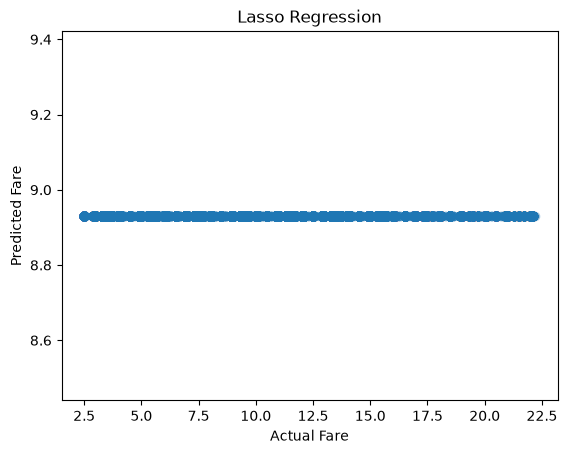

In [15]:
# 7. VISUALIZATION
plt.scatter(y_test, pred, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title(name)
plt.show()
